# Heart Disease Classification — Lecture Code

**Workflow**

**PROBLEM → UNDERSTAND → EDA → SPLIT → PREPARE → FIT → PREDICT → EVALUATE → INTERPRET**

Inside **PREDICT**:

**probability → threshold → class**

The main idea throughout the notebook is:

**QUESTION → EVIDENCE → DECISION**


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)


## 1. PROBLEM

**Question:** Can the available patient characteristics, measurements and test-result categories help distinguish heart disease **absent (0)** from **present (1)**?

- One row = one patient observation
- `X` = input features
- `y` = `heart_disease`, the target


## 2. UNDERSTAND — meet the patient before the columns

One row represents **one patient observation**.

Think of a patient coming for a heart assessment:

- We know some basic things: **age and sex**.
- We ask about symptoms and indicators: **chest-pain type, fasting blood sugar, exercise angina**.
- We take measurements: **resting blood pressure and cholesterol**.
- We examine the heart at rest using an **ECG**.
- During exercise we record **maximum heart rate**, **oldpeak** (how much the ECG pattern changes compared with rest), and **slope** (the shape/direction of that pattern at peak exercise).
- Other tests give the **number of major vessels visible** and the **thal test category**.

These are the inputs **X**. From them, the model will predict **y: heart disease absent (0) or present (1)**.

**Key idea:** a stored number is not automatically a numerical measurement. First ask what the value means.


In [3]:
df = pd.read_csv("heart_disease.csv")

print("Shape:", df.shape)
display(df.head())


Shape: (270, 14)


,age,sex,chest_pain,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,slope,major_vessels,thal,heart_disease
0,70.0,1.0,4.0,130.0,322.0,0.0,2.0,109.0,0.0,2.4,2.0,3.0,3.0,1
1,67.0,0.0,3.0,115.0,564.0,0.0,2.0,160.0,0.0,1.6,2.0,0.0,7.0,0
2,57.0,1.0,2.0,124.0,261.0,0.0,0.0,141.0,0.0,0.3,1.0,0.0,7.0,1
3,64.0,1.0,4.0,128.0,263.0,0.0,0.0,105.0,1.0,0.2,2.0,1.0,7.0,0
4,74.0,0.0,2.0,120.0,269.0,0.0,2.0,121.0,1.0,0.2,1.0,1.0,3.0,0


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     270 non-null    float64
 1   sex                     270 non-null    float64
 2   chest_pain              270 non-null    float64
 3   resting_blood_pressure  270 non-null    float64
 4   cholesterol             270 non-null    float64
 5   fasting_blood_sugar     270 non-null    float64
 6   resting_ecg             270 non-null    float64
 7   max_heart_rate          270 non-null    float64
 8   exercise_angina         270 non-null    float64
 9   oldpeak                 270 non-null    float64
 10  slope                   270 non-null    float64
 11  major_vessels           270 non-null    float64
 12  thal                    270 non-null    float64
 13  heart_disease           270 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 29.7 KB


In [4]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
age,270.0,54.433333,9.109067,29.0,48.0,55.0,61.0,77.0
sex,270.0,0.677778,0.468195,0.0,0.0,1.0,1.0,1.0
chest_pain,270.0,3.174074,0.950090,1.0,3.0,3.0,4.0,4.0
resting_blood_pressure,270.0,131.344444,17.861608,94.0,120.0,130.0,140.0,200.0
cholesterol,270.0,249.659259,51.686237,126.0,213.0,245.0,280.0,564.0
fasting_blood_sugar,270.0,0.148148,0.355906,0.0,0.0,0.0,0.0,1.0
resting_ecg,270.0,1.022222,0.997891,0.0,0.0,2.0,2.0,2.0
max_heart_rate,270.0,149.677778,23.165717,71.0,133.0,153.5,166.0,202.0
exercise_angina,270.0,0.329630,0.470952,0.0,0.0,0.0,1.0,1.0
oldpeak,270.0,1.050000,1.145210,0.0,0.0,0.8,1.6,6.2


In [5]:
# Check missing values
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("missing_values")
)


,missing_values
age,0
sex,0
chest_pain,0
resting_blood_pressure,0
cholesterol,0
fasting_blood_sugar,0
resting_ecg,0
max_heart_rate,0
exercise_angina,0
oldpeak,0


### Organize features by meaning

These groups come from the dataset documentation and the meaning of the variables — not simply from the pandas dtype.


In [6]:
continuous_features = [
    "age",
    "resting_blood_pressure",
    "cholesterol",
    "max_heart_rate",
    "oldpeak"
]

count_features = [
    "major_vessels"
]

# Both measured values and genuine counts are numerical.
# For Logistic Regression, scale them together.
numerical_features = continuous_features + count_features

nominal_features = [
    "chest_pain",
    "resting_ecg",
    "thal"
]

ordinal_features = [
    "slope"
]

binary_features = [
    "sex",
    "fasting_blood_sugar",
    "exercise_angina"
]

target = "heart_disease"


### What does each input mean?

| Feature | Simple patient meaning | How to read the stored value |
|---|---|---|
| `age` | Patient's age | years |
| `sex` | Sex recorded for the patient | binary category already encoded as 0/1 |
| `chest_pain` | Type of chest pain | category code 1–4, not an amount of pain |
| `resting_blood_pressure` | Systolic blood pressure while resting | mm Hg |
| `cholesterol` | Serum cholesterol measurement | mg/dl |
| `fasting_blood_sugar` | Is fasting blood sugar above 120 mg/dl? | binary category already encoded: 0 = no, 1 = yes |
| `resting_ecg` | Resting ECG result | category code |
| `max_heart_rate` | Highest heart rate reached during exercise | beats per minute |
| `exercise_angina` | Did exercise cause angina? | binary category already encoded: 0 = no, 1 = yes |
| `oldpeak` | Amount of ECG ST change during exercise compared with rest | an amount; larger value = more measured change |
| `slope` | Shape/direction of the ST segment at peak exercise | 1 = upsloping, 2 = flat, 3 = downsloping |
| `major_vessels` | Number of major vessels visible | count 0–3 |
| `thal` | Thal test-result category | category code 3/6/7 |

The purpose is **not to diagnose patients from one value**. We need enough domain meaning to interpret the data correctly and choose an appropriate representation.


## 3. EDA — explore individual variables

For measured numerical variables, look at **range, centre, spread, shape and unusual values**.


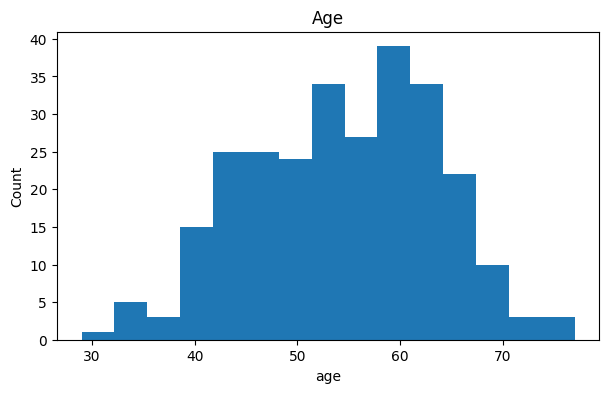

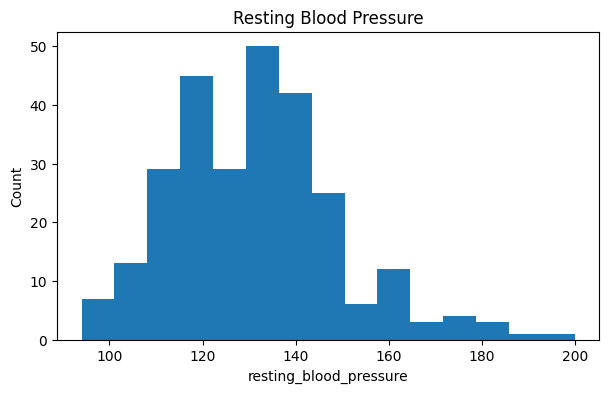

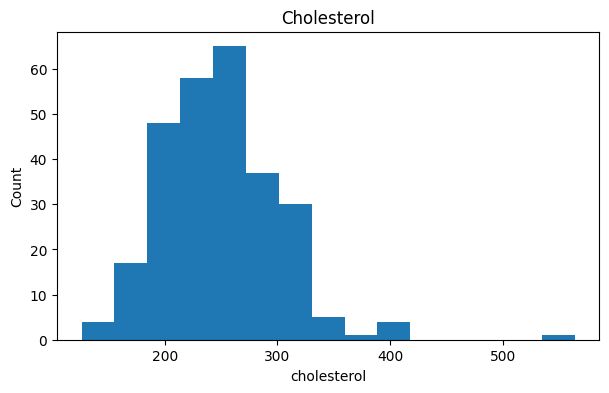

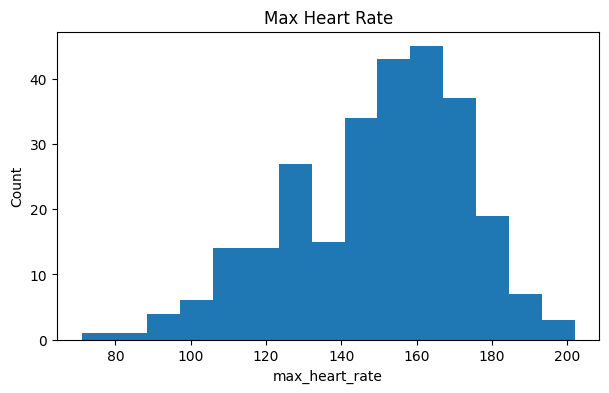

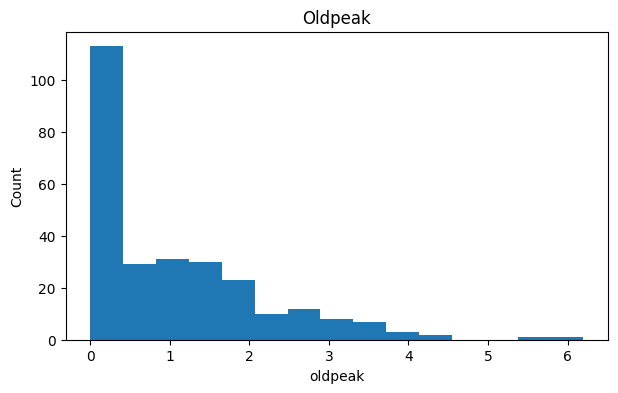

In [7]:
for feature in continuous_features:
    plt.figure(figsize=(7, 4))
    df[feature].plot(kind="hist", bins=15)
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.title(feature.replace("_", " ").title())
    plt.show()


### Discrete numerical count

`major_vessels` is a genuine count. A bar chart is more natural than treating it as a continuous measurement.


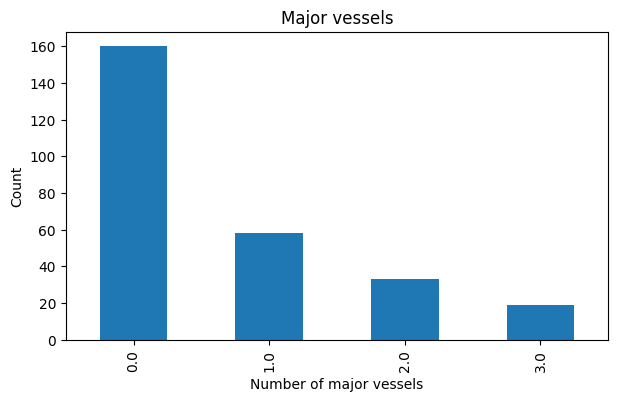

In [8]:
counts = df["major_vessels"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
counts.plot(kind="bar")
plt.xlabel("Number of major vessels")
plt.ylabel("Count")
plt.title("Major vessels")
plt.show()


### Categorical variables

For categories, inspect how often each category occurs.


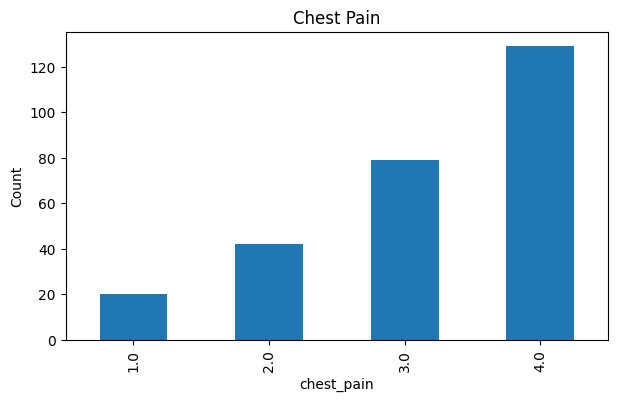

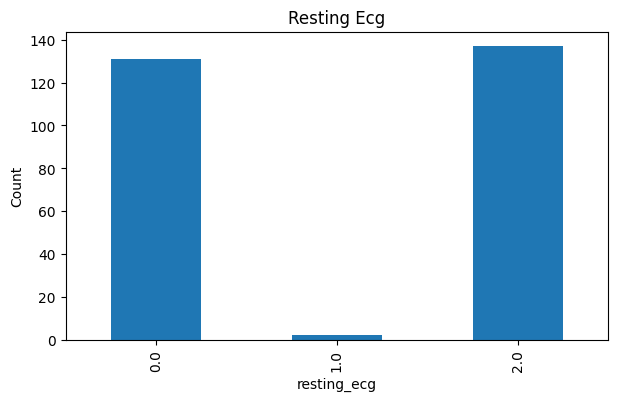

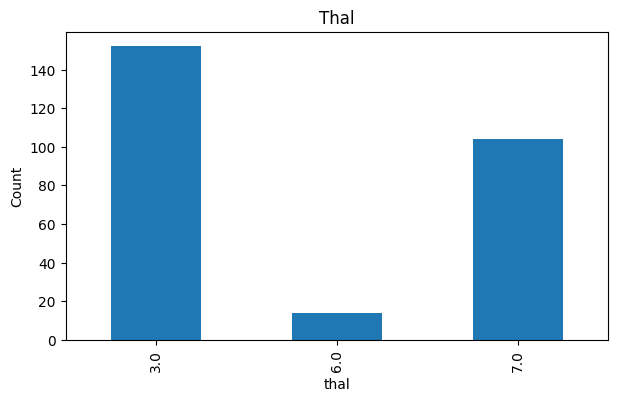

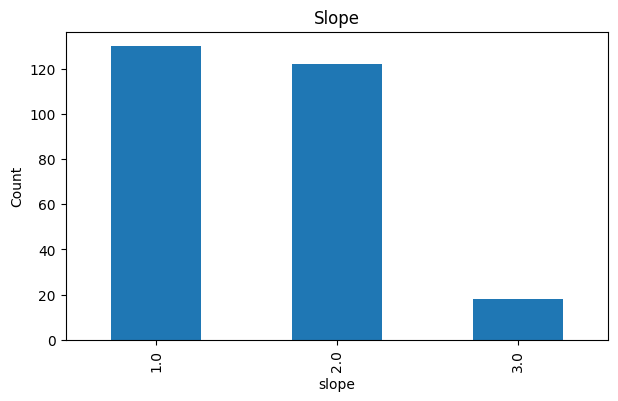

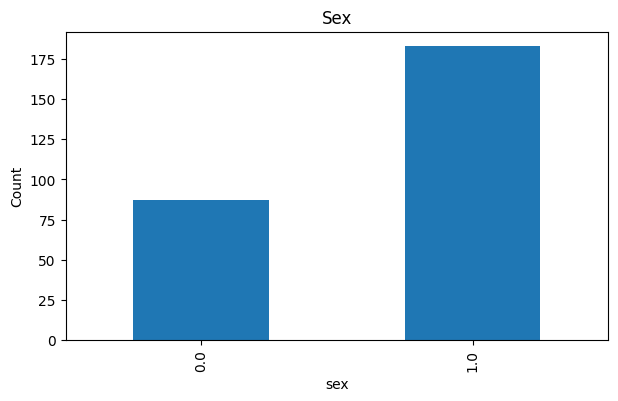

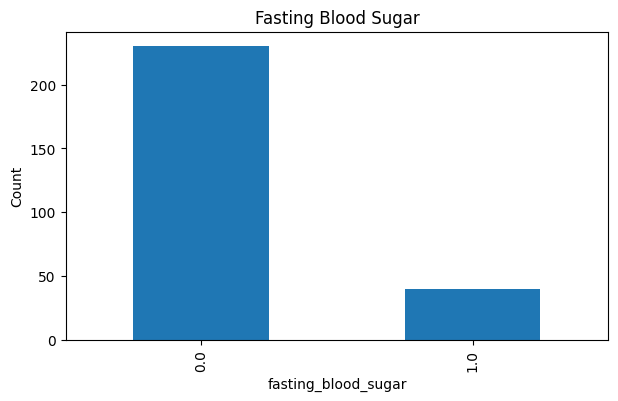

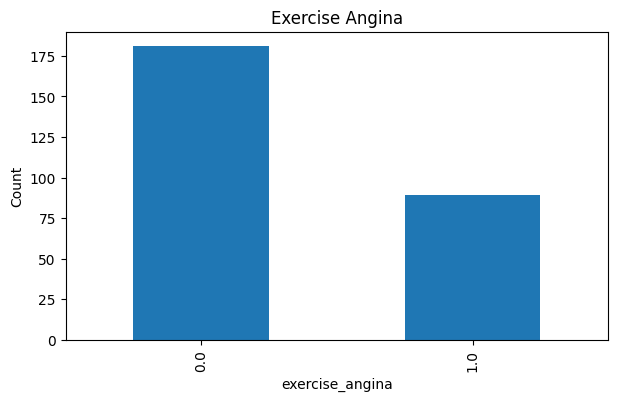

In [9]:
eda_categorical_features = nominal_features + ordinal_features + binary_features

for feature in eda_categorical_features:
    counts = df[feature].value_counts().sort_index()

    plt.figure(figsize=(7, 4))
    counts.plot(kind="bar")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.title(feature.replace("_", " ").title())
    plt.show()


## 4. EDA — inspect the target

**Question:** Are both classes represented?


In [10]:
target_counts = df[target].value_counts().sort_index()
target_proportions = df[target].value_counts(normalize=True).sort_index()

display(pd.DataFrame({
    "count": target_counts,
    "proportion": target_proportions
}))


,count,proportion
heart_disease,,
0,150,0.555556
1,120,0.444444


## 5. EDA — relate X to y

Now ask whether the pattern of an input feature changes between heart-disease **absent (0)** and **present (1)**.

EDA can show **association**. It does not establish **causation**.


### A. Measured numerical X vs categorical y

For every measured numerical feature, use the same reasoning:

**QUESTION → EVIDENCE → WHAT DO WE SEE? → DECISION**

1. What does this measurement mean for the patient?
2. Do the disease-absent and disease-present distributions differ?
3. How much do the groups overlap?
4. Does the feature appear to contain useful predictive information?

The histogram shows the **shape and overlap** of the two distributions.  
The boxplot gives a compact view of their **centre, spread and unusual values**.


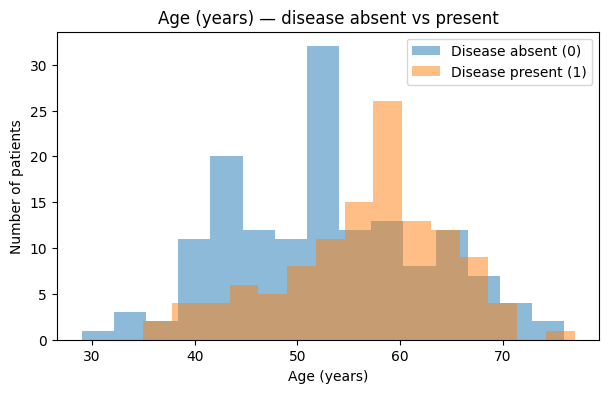

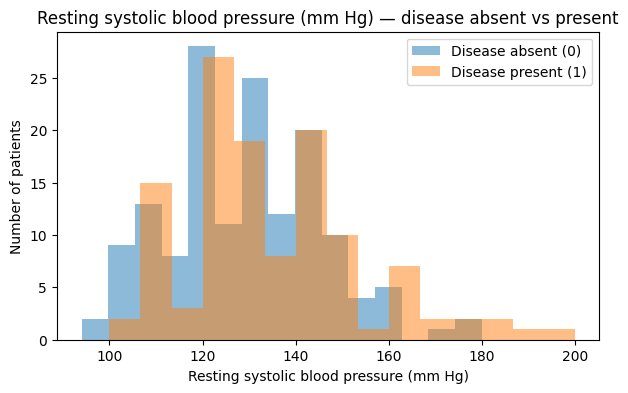

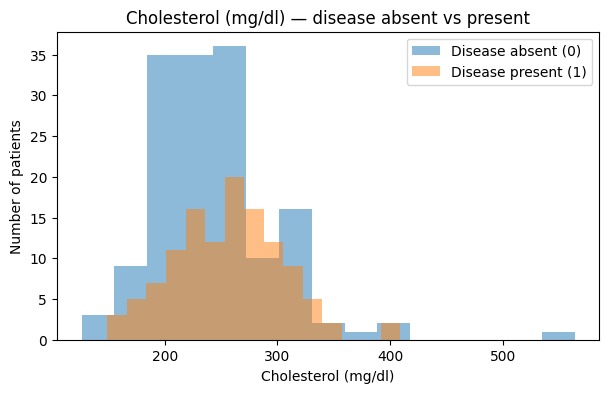

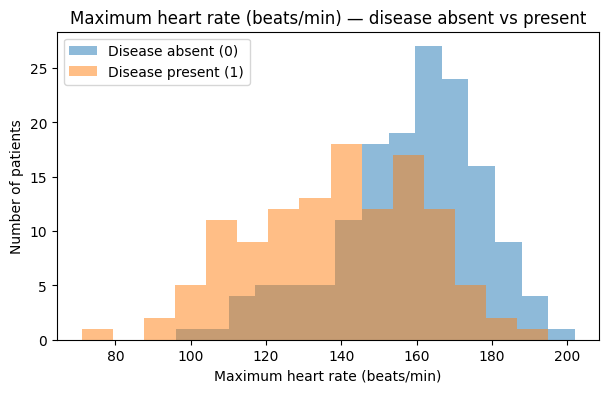

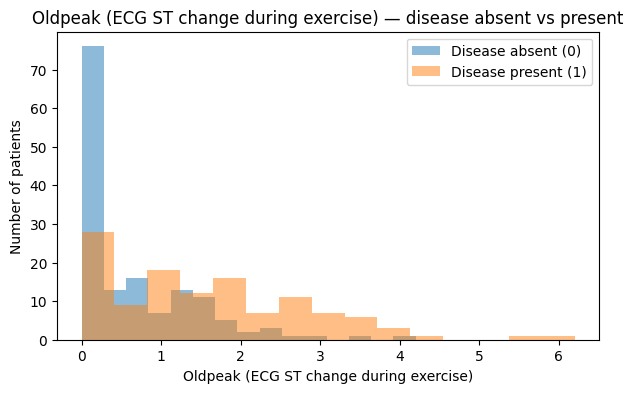

In [11]:
feature_labels = {
    "age": "Age (years)",
    "resting_blood_pressure": "Resting systolic blood pressure (mm Hg)",
    "cholesterol": "Cholesterol (mg/dl)",
    "max_heart_rate": "Maximum heart rate (beats/min)",
    "oldpeak": "Oldpeak (ECG ST change during exercise)"
}

for feature in continuous_features:
    plt.figure(figsize=(7, 4))

    df.loc[df[target] == 0, feature].plot(
        kind="hist", bins=15, alpha=0.5, label="Disease absent (0)"
    )
    df.loc[df[target] == 1, feature].plot(
        kind="hist", bins=15, alpha=0.5, label="Disease present (1)"
    )

    plt.xlabel(feature_labels[feature])
    plt.ylabel("Number of patients")
    plt.title(f"{feature_labels[feature]} — disease absent vs present")
    plt.legend()
    plt.show()


<Figure size 600x400 with 0 Axes>

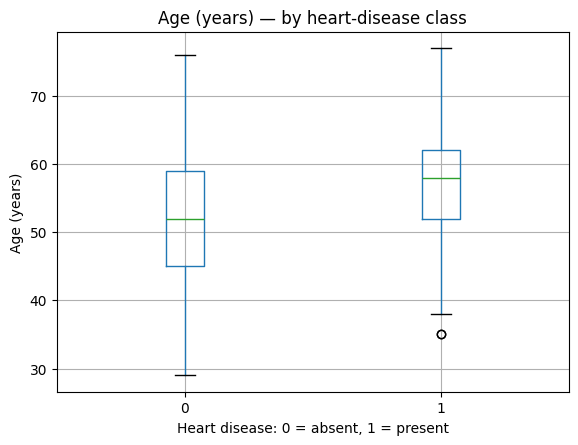

<Figure size 600x400 with 0 Axes>

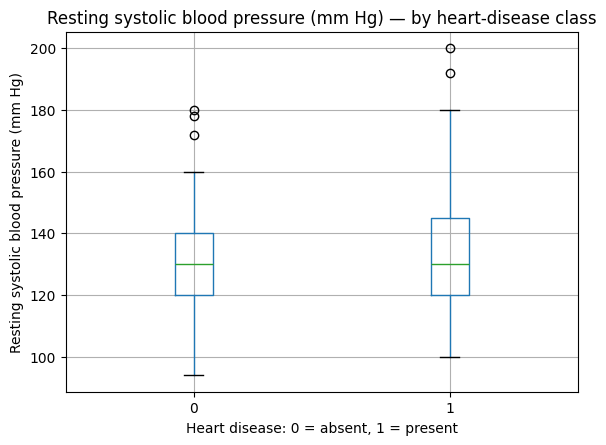

<Figure size 600x400 with 0 Axes>

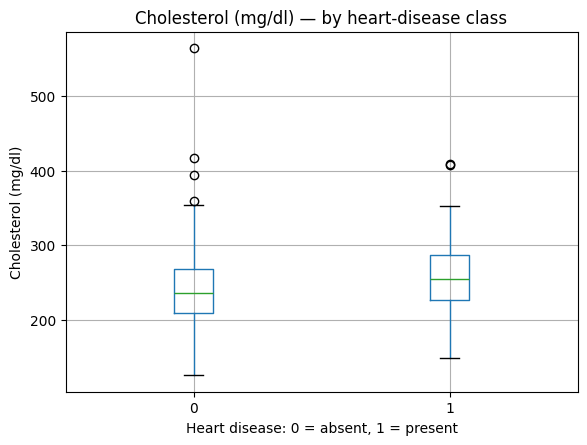

<Figure size 600x400 with 0 Axes>

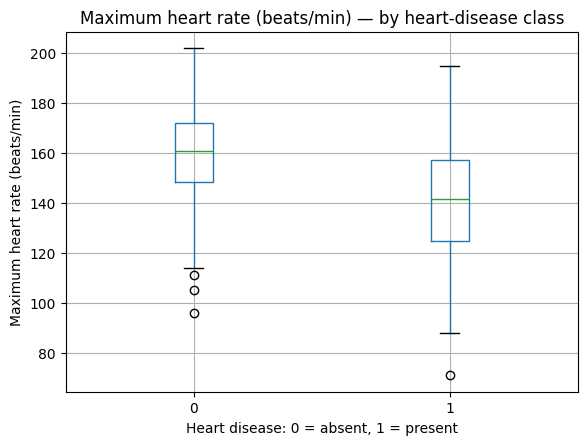

<Figure size 600x400 with 0 Axes>

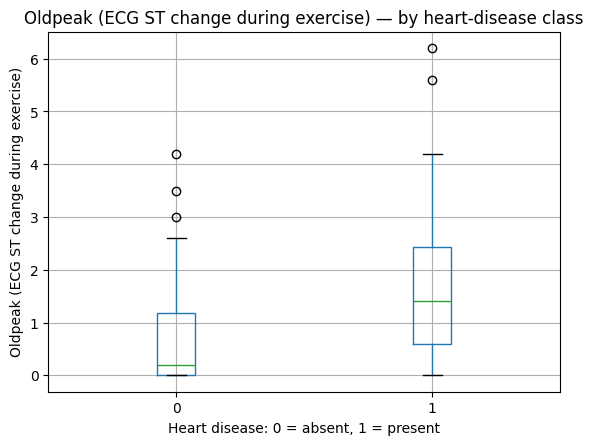

Disease absent (0)  Disease present (1)
age                    mean                 52.71                56.59
                       median               52.00                58.00
resting_blood_pressure mean                128.87               134.44
                       median              130.00               130.00
cholesterol            mean                244.21               256.47
                       median              236.00               255.50
max_heart_rate         mean                158.33               138.86
                       median              161.00               141.50
oldpeak                mean                  0.62                 1.58
                       median                0.20                 1.40

In [12]:
for feature in continuous_features:
    plt.figure(figsize=(6, 4))
    df.boxplot(column=feature, by=target)
    plt.suptitle("")
    plt.title(f"{feature_labels[feature]} — by heart-disease class")
    plt.xlabel("Heart disease: 0 = absent, 1 = present")
    plt.ylabel(feature_labels[feature])
    plt.show()

# Small numerical summary to support what we see in the plots
continuous_summary = (
    df.groupby(target)[continuous_features]
      .agg(["mean", "median"])
      .T
)

continuous_summary.columns = ["Disease absent (0)", "Disease present (1)"]
display(continuous_summary.round(2))


### What do the numerical plots show?

**Age**  
Patients with heart disease tend to be **older** in this sample. The two groups still overlap substantially, so age alone cannot determine the class.

**Resting blood pressure**  
The centres of the two groups are quite similar and there is substantial overlap. The disease-present group is somewhat higher overall, but resting blood pressure alone separates the classes poorly.

**Cholesterol**  
The disease-present group tends to have somewhat higher values, but the distributions overlap strongly. A medically relevant variable does not have to show a dramatic separation in this particular dataset.

**Maximum heart rate**  
The disease-present group tends to reach a **lower maximum heart rate** during the exercise test. The difference is clearer than for resting blood pressure or cholesterol, although the groups still overlap.

**Oldpeak**  
`oldpeak` measures how much the ECG ST pattern changes during exercise compared with rest. The disease-present group tends to have **larger oldpeak values**. This is another relatively clear difference, but it is not a diagnostic rule.

**Overall:** no single measurement perfectly separates the two classes. This is why a classifier combines information from several features.


### Correlation as one numerical summary

After looking at the distributions, correlation gives us one additional numerical summary.

Because `heart_disease` is coded **0 = absent** and **1 = present**:

- **positive correlation** → larger feature values tend to occur more with disease present;
- **negative correlation** → larger feature values tend to occur more with disease absent;
- **closer to 0** → weaker linear association with the target.

Correlation supports the visual EDA; it does **not** prove causation, and it is **not** by itself a rule for deleting a feature.


In [13]:
continuous_correlations = (
    df[continuous_features + [target]]
    .corr()[target]
    .drop(target)
    .sort_values()
)

display(
    continuous_correlations
    .rename("Correlation with heart_disease")
    .to_frame()
    .round(3)
)


,Correlation with heart_disease
max_heart_rate,-0.419
cholesterol,0.118
resting_blood_pressure,0.155
age,0.212
oldpeak,0.418


### Read the correlations together with the plots

- `max_heart_rate` has a **negative** association: higher maximum heart rates tend to occur more in the disease-absent group.
- `oldpeak` has a **positive** association: larger oldpeak values tend to occur more in the disease-present group.
- `age` shows a weaker positive association.
- `resting_blood_pressure` and `cholesterol` show weaker linear associations in this sample.

Do not translate these directly into medical rules. They describe patterns in this dataset.


### B. Discrete count — `major_vessels`

**Question:** Does the observed heart-disease proportion differ across vessel counts?


heart_disease,0,1
major_vessels,,
0.0,0.750,0.250
1.0,0.345,0.655
2.0,0.212,0.788
3.0,0.158,0.842


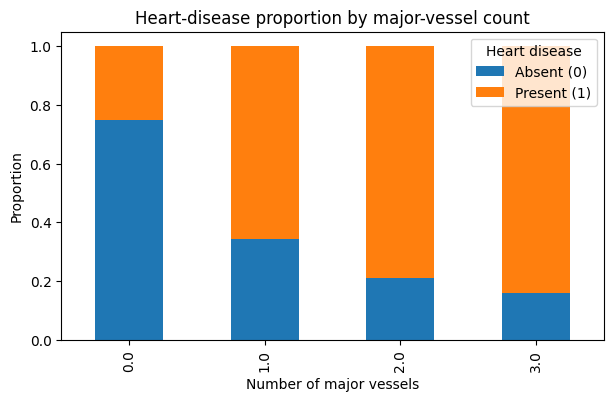

In [14]:
major_vessels_proportions = pd.crosstab(
    df["major_vessels"],
    df[target],
    normalize="index"
)

display(major_vessels_proportions.round(3))

major_vessels_proportions.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.xlabel("Number of major vessels")
plt.ylabel("Proportion")
plt.title("Heart-disease proportion by major-vessel count")
plt.legend(["Absent (0)", "Present (1)"], title="Heart disease")
plt.show()


### What do we see?

As the observed vessel count increases, the **proportion of disease-present patients increases in this sample**.

This makes `major_vessels` potentially useful predictive evidence. But it is still an **association in the dataset**, not a statement that the count causes heart disease.


### C. Categorical X vs categorical y

For a categorical predictor, asking for a mean is usually not the useful question.

Instead ask:

> **Within each category, what proportion of patients have heart disease absent or present?**

Start with **chest pain** as the worked example. Remember: values 1–4 are **types of chest pain**, not increasing amounts of pain.


heart_disease,0,1
chest_pain,,
1.0,15,5
2.0,35,7
3.0,62,17
4.0,38,91


heart_disease,0,1
chest_pain,,
1.0,0.750,0.250
2.0,0.833,0.167
3.0,0.785,0.215
4.0,0.295,0.705


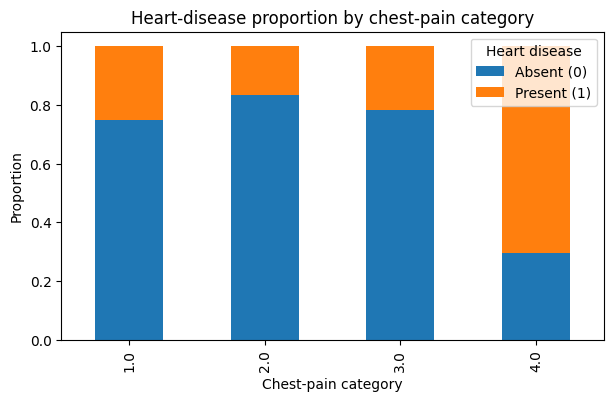

In [15]:
# Example: chest pain
display(pd.crosstab(df["chest_pain"], df[target]))

chest_pain_proportions = pd.crosstab(
    df["chest_pain"],
    df[target],
    normalize="index"
)

display(chest_pain_proportions.round(3))

chest_pain_proportions.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.xlabel("Chest-pain category")
plt.ylabel("Proportion")
plt.title("Heart-disease proportion by chest-pain category")
plt.legend(["Absent (0)", "Present (1)"], title="Heart disease")
plt.show()


### Chest pain — what do we see?

The proportion of heart disease is **not the same across chest-pain categories**. In this sample, category 4 has a much larger disease-present proportion than categories 1–3.

So chest-pain **type** contains useful predictive information.

**Do not conclude:** a larger chest-pain code means “more pain” or that chest-pain type causes heart disease. The numbers are category labels.



chest_pain


heart_disease,Disease absent (0),Disease present (1)
chest_pain,,
1.0,0.750,0.250
2.0,0.833,0.167
3.0,0.785,0.215
4.0,0.295,0.705


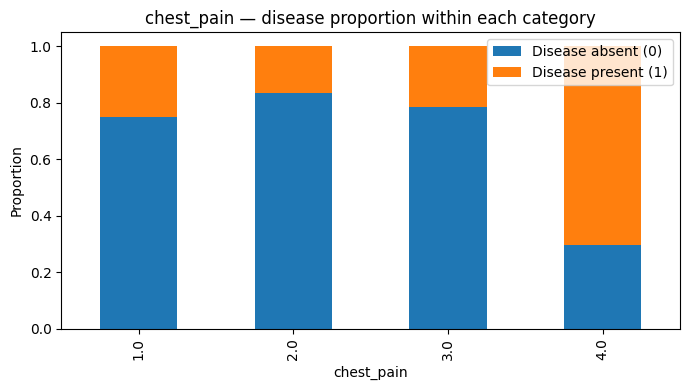


resting_ecg


heart_disease,Disease absent (0),Disease present (1)
resting_ecg,,
0.0,0.649,0.351
1.0,0.500,0.500
2.0,0.467,0.533


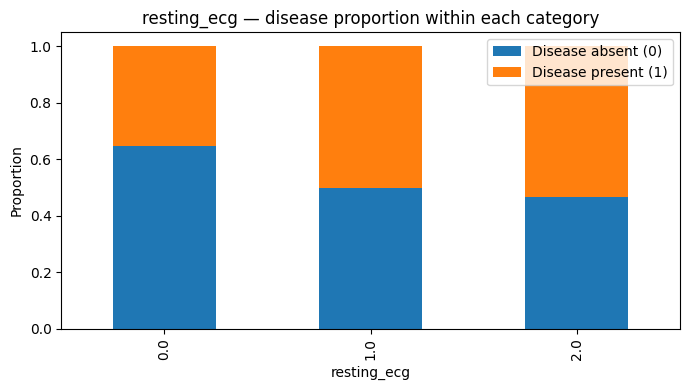


thal


heart_disease,Disease absent (0),Disease present (1)
thal,,
3.0,0.783,0.217
6.0,0.429,0.571
7.0,0.240,0.760


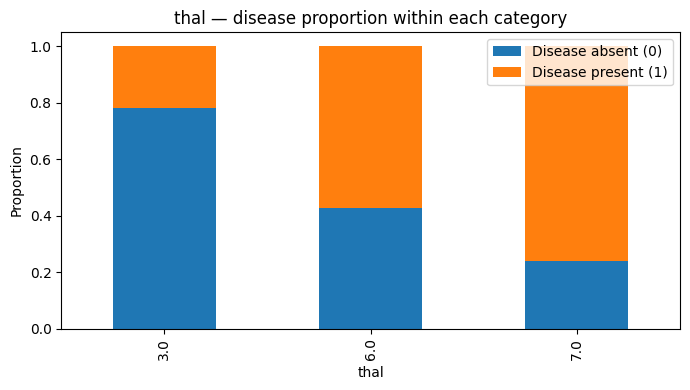


slope


heart_disease,Disease absent (0),Disease present (1)
slope,,
1.0,0.754,0.246
2.0,0.361,0.639
3.0,0.444,0.556


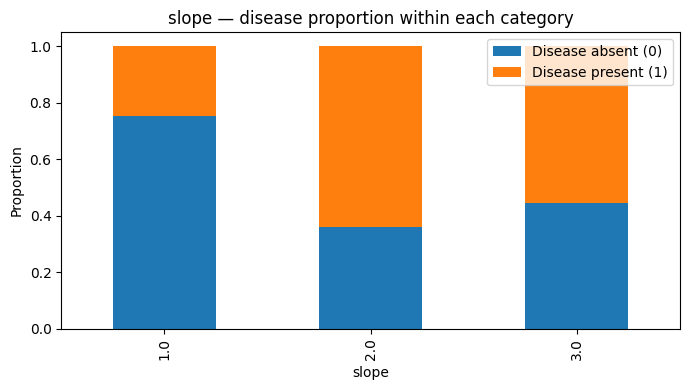


sex


heart_disease,Disease absent (0),Disease present (1)
sex,,
0.0,0.770,0.230
1.0,0.454,0.546


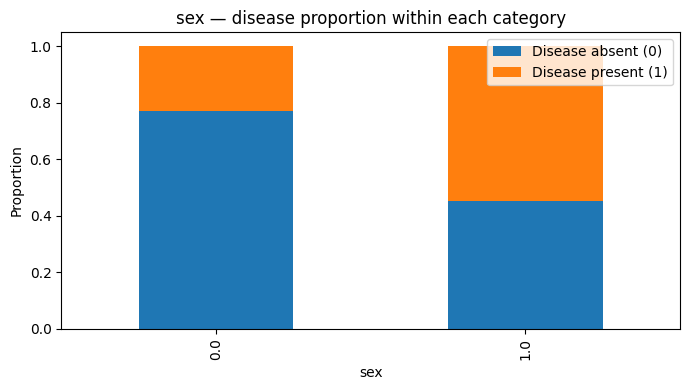


fasting_blood_sugar


heart_disease,Disease absent (0),Disease present (1)
fasting_blood_sugar,,
0.0,0.552,0.448
1.0,0.575,0.425


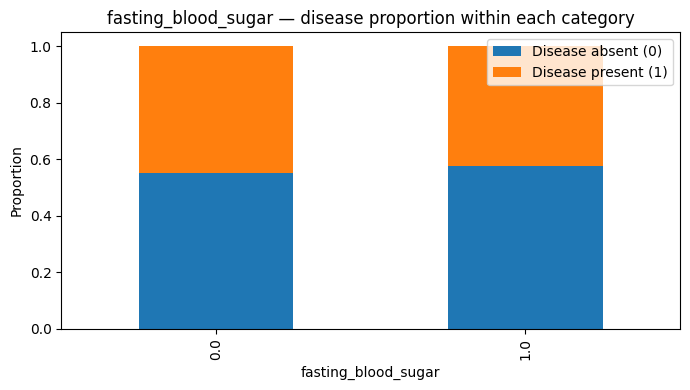


exercise_angina


heart_disease,Disease absent (0),Disease present (1)
exercise_angina,,
0.0,0.702,0.298
1.0,0.258,0.742


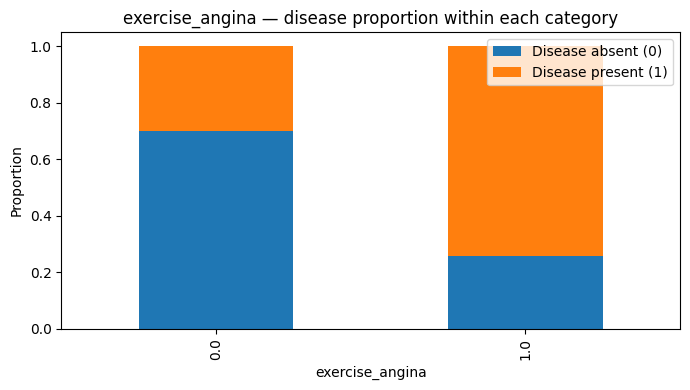

In [16]:
# Apply the same question to the remaining categorical predictors
categorical_results = {}

for feature in nominal_features + ordinal_features + binary_features:
    proportions = pd.crosstab(
        df[feature],
        df[target],
        normalize="index"
    )

    categorical_results[feature] = proportions

    print(f"\n{feature}")
    display(
        proportions.rename(
            columns={0: "Disease absent (0)", 1: "Disease present (1)"}
        ).round(3)
    )

    proportions.plot(
        kind="bar",
        stacked=True,
        figsize=(7, 4)
    )
    plt.xlabel(feature)
    plt.ylabel("Proportion")
    plt.title(f"{feature} — disease proportion within each category")
    plt.legend(["Disease absent (0)", "Disease present (1)"])
    plt.tight_layout()
    plt.show()


### What do the categorical comparisons suggest?

Use the plots to describe the pattern before thinking about preprocessing.

- **Chest pain:** disease proportions differ clearly across chest-pain types.
- **Exercise angina:** patients who experience angina during exercise have a higher disease-present proportion in this sample.
- **Thal:** disease proportions differ clearly across thal categories.
- **Slope:** disease proportions differ across the ordered slope categories.
- **Sex** and **resting ECG:** there are differences, but interpret them as associations in this sample.
- **Fasting blood sugar:** the two categories show relatively little difference on their own.

The important ML lesson is not to diagnose from any one category. We are asking whether each feature contributes evidence that a classifier can combine with the other features.


## EDA SUMMARY — what decisions follow?

**QUESTION:** Do the inputs contain patterns related to the target?

**EVIDENCE:**  
- some numerical distributions differ between disease absent and present;
- some categorical disease proportions differ across categories;
- every comparison still contains overlap or uncertainty.

**DECISION:**  
- keep the patient features as candidate predictors;
- represent each feature according to what its values mean;
- do not treat category codes as measured quantities;
- no missing values means no imputation is needed here;
- split before learning preprocessing or model parameters.

EDA gives us **clues for prediction**, not deterministic rules and not causal proof.


## 6. SPLIT — protect unseen TEST data

**TRAIN teaches. TEST checks.**

For this classification problem, we use the target classes when stratifying so TRAIN and TEST contain approximately similar proportions of class 0 and class 1.


In [17]:
X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN target proportions:")
display(y_train.value_counts(normalize=True).sort_index())

print("TEST target proportions:")
display(y_test.value_counts(normalize=True).sort_index())


TRAIN target proportions:


heart_disease
0    0.555556
1    0.444444
Name: proportion, dtype: float64

TEST target proportions:


heart_disease
0    0.555556
1    0.444444
Name: proportion, dtype: float64

## 7. PREPARE — represent X according to meaning

- measured numerical → scale
- discrete count → keep numerical
- nominal category → one-hot encode
- ordered category → ordinal encode
- binary 0/1 → keep 0/1

There are no missing values in this supplied dataset, so imputation is not required.


In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),

        ("nominal",
         OneHotEncoder(handle_unknown="ignore"),
         nominal_features),

        ("ordinal",
         OrdinalEncoder(categories=[[1, 2, 3]]),
         ordinal_features)
    ],
    remainder="passthrough"
)


### DEFINE the complete pipeline

Creating the Pipeline defines the sequence. **Nothing has been learned from the data yet.**


In [19]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])


## 8. FIT — learn from TRAIN

`fit()` learns any data-dependent preprocessing information from `X_train` and the Logistic Regression model parameters from the prepared `X_train` together with `y_train`.


In [20]:
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

## 9. PREDICT — class and probability

`predict()` gives a class.

`predict_proba()` gives probabilities. `[:, 1]` selects the probability of class 1: heart disease PRESENT.


In [21]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

preview = pd.DataFrame({
    "actual": y_test.to_numpy()[:10],
    "predicted_probability_class_1": y_probability[:10],
    "predicted_class": y_pred[:10]
})

display(preview.round(3))


,actual,predicted_probability_class_1,predicted_class
0,0,0.051,0
1,0,0.169,0
2,0,0.072,0
3,1,0.937,1
4,0,0.341,0
5,0,0.069,0
6,0,0.049,0
7,1,0.971,1
8,1,0.653,1
9,1,0.706,1


## 10. EVALUATE — start with the confusion matrix

Positive class = heart disease **PRESENT (1)**.


TN = 26
FP = 4
FN = 2
TP = 22


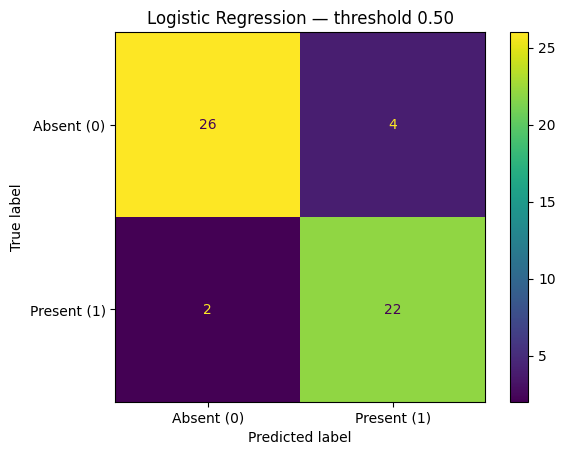

In [22]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("TN =", tn)
print("FP =", fp)
print("FN =", fn)
print("TP =", tp)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Absent (0)", "Present (1)"]
).plot()

plt.title("Logistic Regression — threshold 0.50")
plt.show()


In [23]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics = pd.Series({
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1
})

display(metrics.to_frame("score").round(3))


,score
Accuracy,0.889
Precision,0.846
Recall,0.917
F1,0.880


## 11. THRESHOLD — probability becomes a class

The fitted model produces probabilities. The threshold turns those probabilities into class decisions.

Compare the same two thresholds used in Assignment 2: **0.50 and 0.40**.

Changing the threshold does **not** retrain the model and does **not** change the predicted probabilities.


In [24]:
threshold_results = []

for threshold in [0.50, 0.40]:
    y_pred_threshold = (y_probability >= threshold).astype(int)

    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        y_test, y_pred_threshold
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1": f1_score(y_test, y_pred_threshold),
        "False positives": fp_t,
        "False negatives": fn_t
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(3))


,Threshold,Accuracy,Precision,Recall,F1,False positives,False negatives
0,0.5,0.889,0.846,0.917,0.880,4,2
1,0.4,0.852,0.786,0.917,0.846,6,2


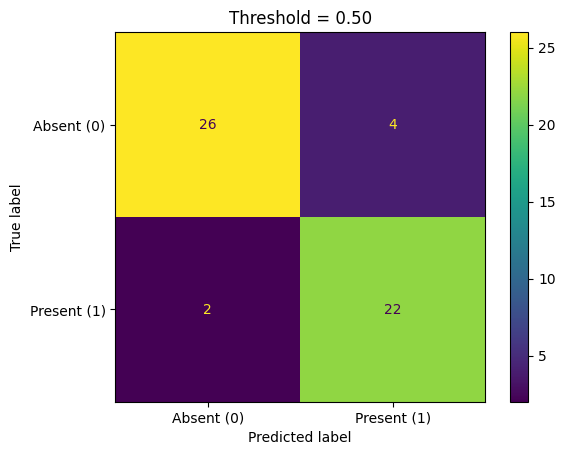

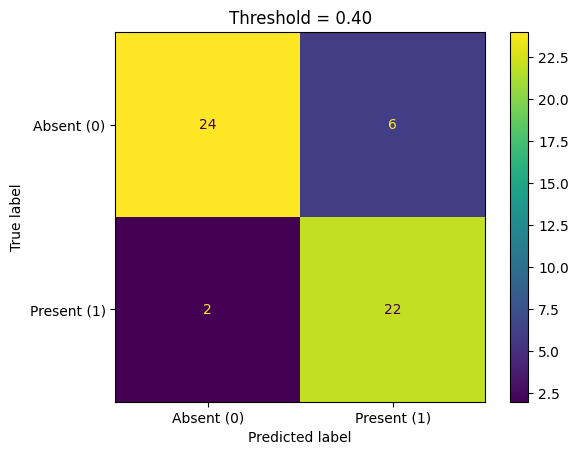

In [25]:
for threshold in [0.50, 0.40]:
    y_pred_threshold = (y_probability >= threshold).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_threshold,
        display_labels=["Absent (0)", "Present (1)"]
    )

    plt.title(f"Threshold = {threshold:.2f}")
    plt.show()


### Questions

- What happened to the number of false negatives?
- What happened to the number of false positives?
- What happened to recall?
- What happened to precision?
- Was the model fitted again?
- Did the predicted probabilities change?


## 12. ROC/AUC — lecture extension

ROC looks at performance across many possible thresholds.  
AUC summarizes how well the model ranks/separates positive and negative observations across thresholds.

**AUC is not accuracy and does not choose a threshold.**

This section is part of the lecture, but it is **not required in Assignment 2**.


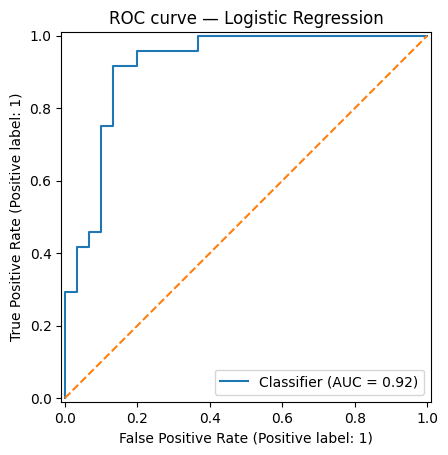

ROC AUC: 0.918


In [26]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC curve — Logistic Regression")
plt.show()

auc = roc_auc_score(y_test, y_probability)
print("ROC AUC:", round(auc, 3))


# Final map

**MEANING → TYPE → EDA EVIDENCE → SPLIT → PREPARE → FIT → PROBABILITY → THRESHOLD → CLASS → ERRORS → METRICS → INTERPRET**

Remember:

- A stored number is not automatically a numerical measurement.
- Association is not causation.
- DEFINE specifies the workflow; FIT learns from TRAIN.
- TEST is for unseen evaluation.
- A probability is not a class until a threshold is applied.
- Accuracy alone does not describe the kinds of mistakes the classifier makes.
